# Milestone 3 – Task 6: Model Performance Comparison

## Objective

Compare the previously evaluated Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost models for predicting Kickstarter campaign success.

**This notebook consolidates the evaluation results from Tasks 2–5. It does not train or refit any models.** Metrics and confusion matrices are recorded from the individual model notebooks. KNN's ROC-AUC is included from the updated Task 4 evaluation.

## 1. Consolidate Existing Model Results

This section consolidates the evaluation results from the four models developed in Milestone 3: **Logistic Regression, Random Forest, K-Nearest Neighbors (KNN), and XGBoost**. Each model is compared using the same performance metrics—Accuracy, Precision, Recall, F1 Score, and ROC-AUC—along with its confusion matrix. These results provide a consistent basis for evaluating each model’s predictive performance and identifying the strongest candidate for the project.

The comparison uses the recorded results from the individual model notebooks rather than retraining the models or recalculating predictions. If any model notebook is updated, its corresponding metrics and confusion matrix should also be updated here to keep the comparison accurate.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Recorded evaluation results from Tasks 2–5.
# No model fitting or prediction occurs in Task 6.
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6860,
        "Precision": 0.6910,
        "Recall": 0.7713,
        "F1 Score": 0.7289,
        "ROC-AUC": 0.7463
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": 0.7028,
        "Precision": 0.7024,
        "Recall": 0.7929,
        "F1 Score": 0.7449,
        "ROC-AUC": 0.7606
    },
    {
        "Model": "KNN (K=41)",
        "Accuracy": 0.6520,
        "Precision": 0.6567,
        "Recall": 0.7630,
        "F1 Score": 0.7059,
        "ROC-AUC": 0.7049
    },
    {
        "Model": "XGBoost (Tuned)",
        "Accuracy": 0.7032852876,
        "Precision": 0.7023909396,
        "Recall": 0.7945432977,
        "F1 Score": 0.7456306356,
        "ROC-AUC": 0.7670
    }
])

results_percentage = results.set_index("Model").mul(100).round(2)
results_percentage

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,68.60,69.10,77.13,72.89,74.63
Random Forest (Tuned),70.28,70.24,79.29,74.49,76.06
KNN (K=41),65.20,65.67,76.30,70.59,70.49
XGBoost (Tuned),70.33,70.24,79.45,74.56,76.70


## 2. Compare Evaluation Metrics

Accuracy measures overall correctness; precision measures how often campaigns predicted to succeed actually succeed; recall measures how many successful campaigns are identified; F1-score balances precision and recall; and ROC-AUC measures how well the model distinguishes between successful and failed campaigns across classification thresholds.

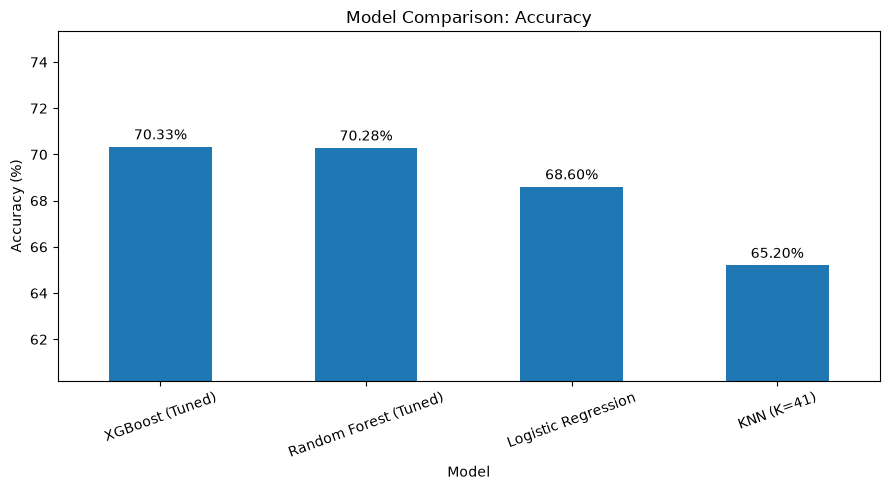

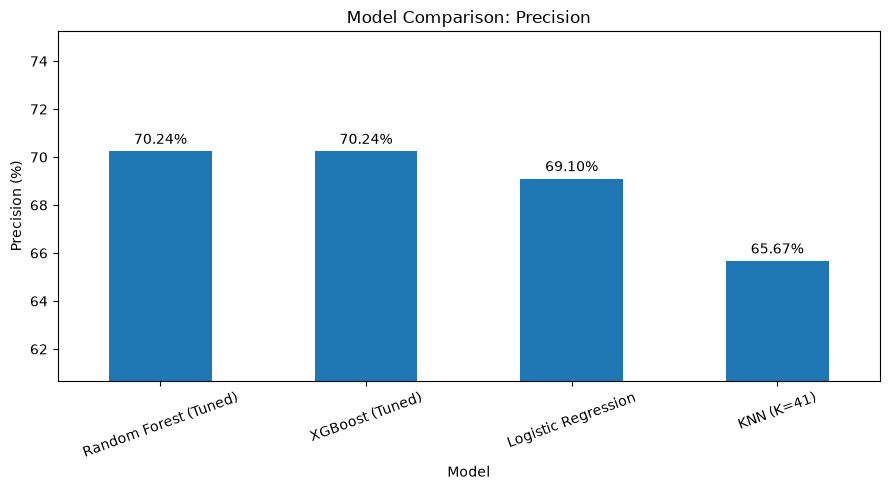

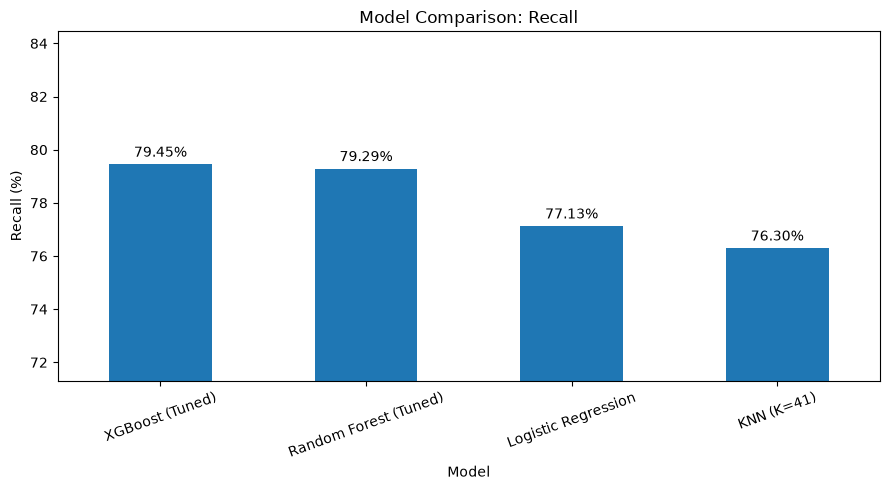

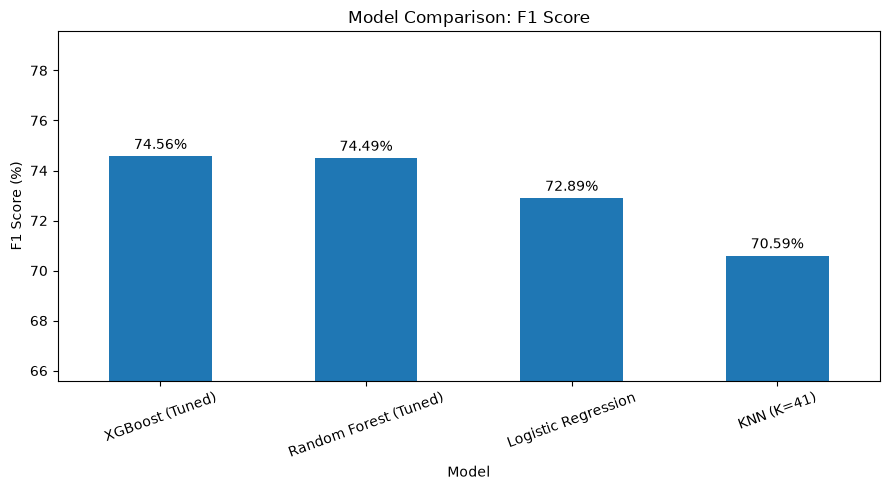

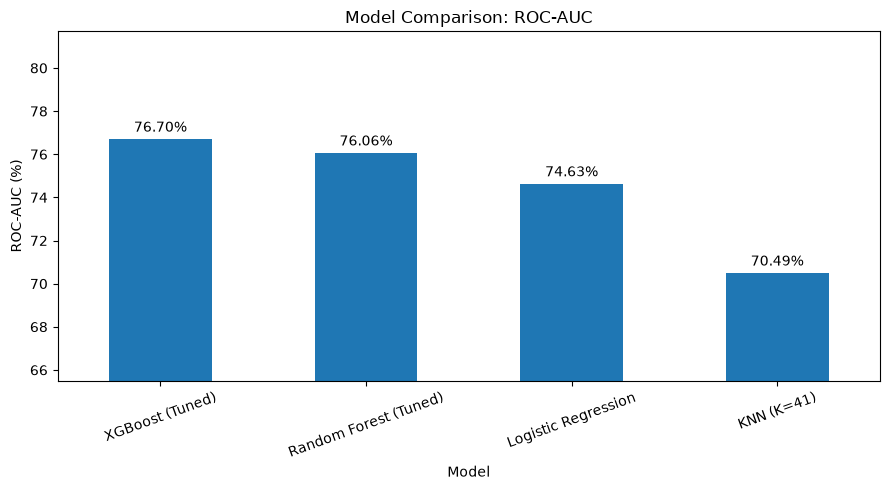

In [38]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_indexed = results.set_index("Model")

for metric in metrics_to_plot:
    values = (results_indexed[metric] * 100).sort_values(ascending=False)

    plt.figure(figsize=(9, 5))
    ax = values.plot(kind="bar", rot=20)
    plt.title(f"Model Comparison: {metric}")
    plt.ylabel(f"{metric} (%)")
    plt.ylim(max(0, values.min() - 5), min(100, values.max() + 5))
    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    plt.xlabel("Model")
    plt.tight_layout()
    plt.show()

## 3. Confusion Matrix Comparison

The matrices below are copied from the individual model evaluations. Rows represent actual outcomes and columns represent predicted outcomes. The class order is **Failed, Successful**.

- **True negative (TN):** failed campaign correctly predicted as failed.
- **False positive (FP):** failed campaign incorrectly predicted as successful.
- **False negative (FN):** successful campaign incorrectly predicted as failed.
- **True positive (TP):** successful campaign correctly predicted as successful.

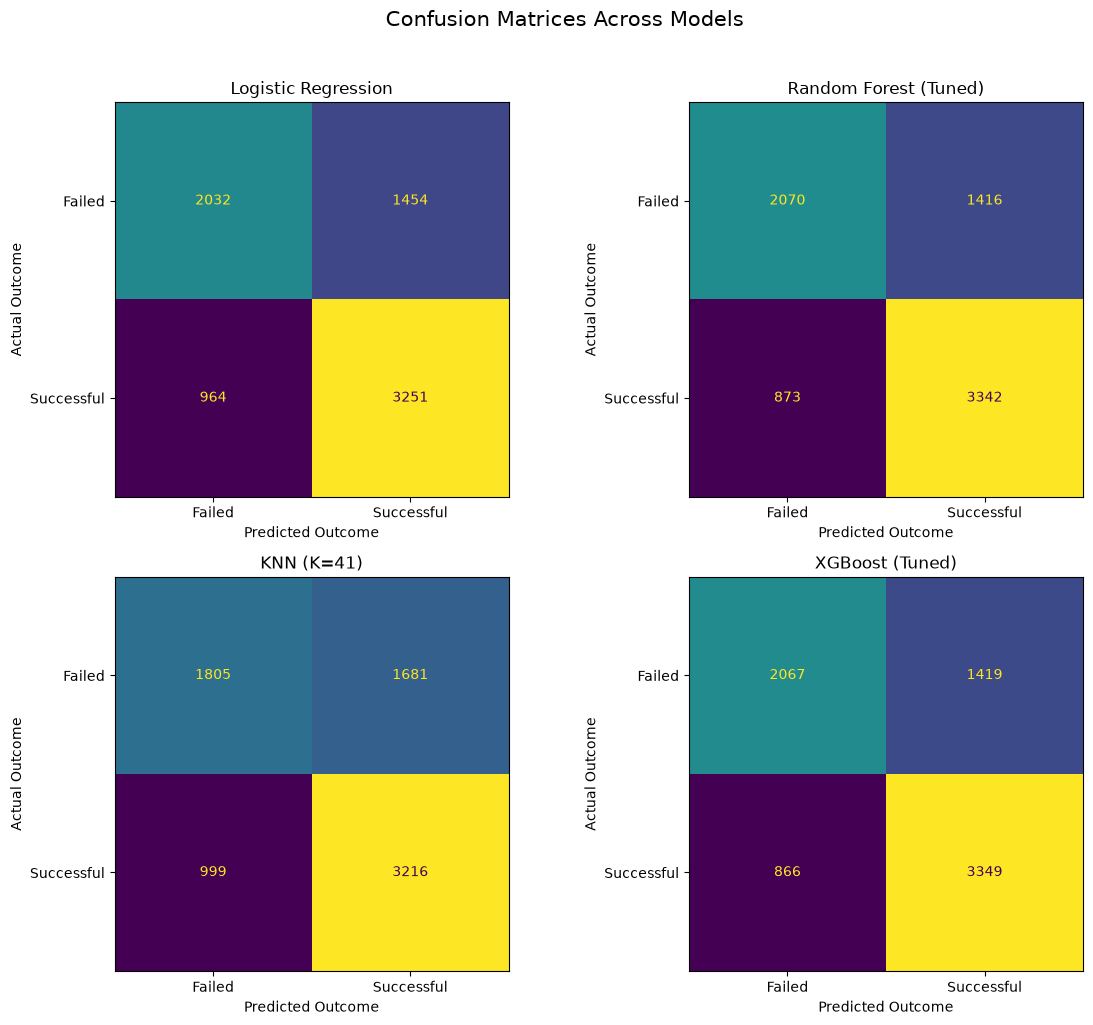

In [39]:
confusion_matrices = {
    "Logistic Regression": np.array([[2032, 1454], [964, 3251]]),
    "Random Forest (Tuned)": np.array([[2070, 1416], [873, 3342]]),
    "KNN (K=41)": np.array([[1805, 1681], [999, 3216]]),
    "XGBoost (Tuned)": np.array([[2067, 1419], [866, 3349]])
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, matrix) in zip(axes.flatten(), confusion_matrices.items()):
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Failed", "Successful"]
    )
    display.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

fig.suptitle("Confusion Matrices Across Models", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## 4. Comparative Model Analysis

The four models demonstrate different levels of predictive performance. Logistic Regression provides a baseline, while Random Forest and XGBoost capture more complex relationships between campaign features and funding outcomes. KNN offers a distance-based approach using standardized numerical features and one-hot-encoded categorical features.

Based on the recorded test results, XGBoost achieved the highest ROC-AUC (76.70%), followed closely by Random Forest (76.06%) and Logistic Regression (74.63%). XGBoost also achieved the highest recall (79.45%) and F1-score (74.56%), indicating a strong balance between identifying successful campaigns and overall predictive performance. Random Forest performed similarly, while KNN had the lowest accuracy (65.20%) and ROC-AUC (70.49%) among the four models.

These results suggest that XGBoost is the strongest candidate based on the current evaluation metrics. However, the final model selection should also consider the project's objective, particularly the trade-off between false positives and false negatives. Because the models' recall values are relatively high compared with their precision, they identify many successful campaigns but also incorrectly classify some unsuccessful campaigns as successful. The confusion matrices provide additional context for evaluating these errors.

## 5. Best Model and Final Discussion

The results support **tuned XGBoost as the leading candidate for the next stage of the project**. Its performance suggests that it can distinguish between successful and unsuccessful campaigns reasonably well, although there is still room for improvement. Tuned Random Forest also performed competitively and should remain an alternative for further evaluation.

One important consideration is the balance between identifying successful campaigns and avoiding incorrect recommendations. The models' results indicate that some unsuccessful campaigns may still be predicted as successful, so the selected model should be evaluated carefully before being used to guide funding decisions.

Overall, XGBoost is the current recommendation based on the available results. The team should validate this selection against the project's original benchmark and use SHAP to investigate which campaign characteristics influence its predictions. These additional steps will help determine whether the model is both effective and suitable for the intended recommendation system.